# Trust regions and cubic regularization on Rosenbrock's function

The Rosenbrock objective has a curved, narrow valley and global minimum at $(1,1)$:
$$f(x,y)=(1-x)^2+100(y-x^2)^2.$$
Its Hessian can be indefinite away from the solution. TRU and ARC receive exact
curvature; SciPy BFGS constructs a positive-definite approximation from gradients.
This notebook shows evaluated points and objective reduction, rather than
interpreting function evaluations as accepted iterations.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1002)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from scipy.optimize import minimize
from galahad_econometrics import Criterion, tru, arc, check_derivatives

def objective(b):
    x, y = b
    return float((1 - x)**2 + 100 * (y - x*x)**2)

def gradient(b):
    x, y = b
    return np.array([2 * (x - 1) - 400*x*(y - x*x), 200*(y - x*x)])

def hessian(b):
    x, y = b
    return np.array([[1200*x*x - 400*y + 2, -400*x], [-400*x, 200.]])

criterion = Criterion(objective, gradient, hessian)
assert max(check_derivatives(criterion, np.array([-1.2, 1.])).values()) < 1e-6
np.linalg.eigvalsh(hessian(np.array([0., 1.])))

array([-398.,  200.])

## Fit from a common start

The callback below records parameter vectors solely for the contour plot.
The solver result's built-in history records objective, gradient norm and elapsed
time. Both traces include rejected trials. Timing here includes instrumentation
and is not a performance benchmark.

In [3]:
start = np.array([-1.2, 1.])
results, paths, rows = {}, {}, []
for name, module in [("TRU", tru), ("ARC", arc)]:
    points = []
    def recorded(b):
        points.append(b.copy())
        return objective(b)
    result = module.solve(Criterion(recorded, gradient, hessian), start, trace=True)
    assert result.success, result.message
    assert np.linalg.norm(result.x - 1) < 1e-6
    results[name], paths[name] = result, np.array(points)
    rows.append({"method": name, "objective": result.fun, "gradient norm": result.optimality,
                 "evaluations": result.nfev, "native status": result.status})

bfgs_points = []
def scipy_objective(b):
    bfgs_points.append(b.copy())
    return objective(b)
bfgs = minimize(scipy_objective, start, jac=gradient, method="BFGS", options={"gtol": 1e-8})
paths["SciPy BFGS"] = np.array(bfgs_points)
assert np.linalg.norm(gradient(bfgs.x)) < 1e-6
rows.append({"method": "SciPy BFGS", "objective": bfgs.fun,
             "gradient norm": np.linalg.norm(gradient(bfgs.x)),
             "evaluations": bfgs.nfev, "native status": bfgs.status})
pd.DataFrame(rows).set_index("method")

,objective,gradient norm,evaluations,native status
method,,,,
TRU,2.8592e-22,7.5015e-10,27,0
ARC,4.9505e-25,3.1368e-11,30,0
SciPy BFGS,4.3509e-25,1.6176e-11,41,0


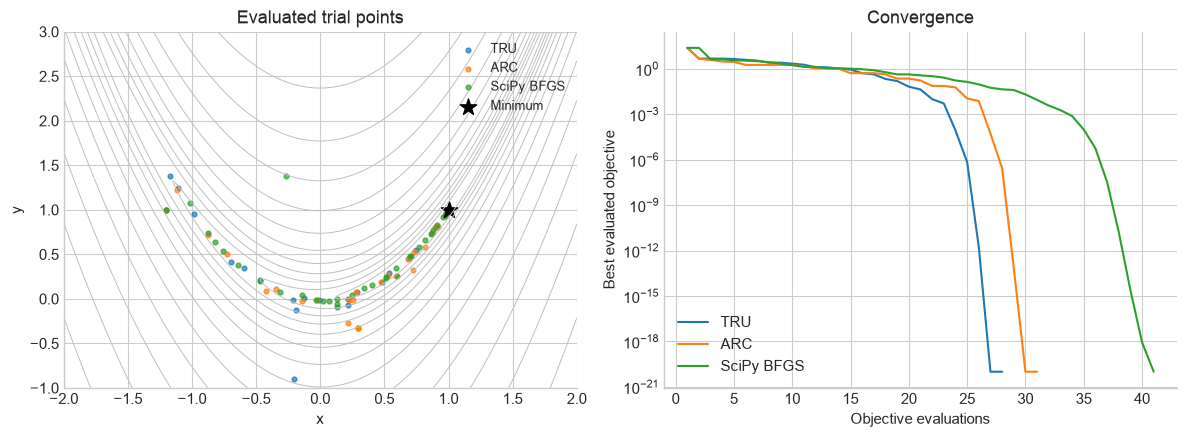

In [4]:
xs, ys = np.linspace(-2., 2., 250), np.linspace(-1., 3., 250)
xx, yy = np.meshgrid(xs, ys)
zz = (1 - xx)**2 + 100 * (yy - xx**2)**2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].contour(xx, yy, np.log10(1 + zz), levels=15, colors="0.75", linewidths=.7)
for name, points in paths.items():
    axes[0].scatter(points[:, 0], points[:, 1], s=12, alpha=.7, label=name)
    values = np.array([objective(point) for point in points])
    axes[1].semilogy(np.arange(1, len(values)+1), np.maximum(np.minimum.accumulate(values), 1e-20),
                     label=name)
axes[0].scatter([1], [1], marker="*", s=150, color="black", label="Minimum")
axes[0].set(xlim=(-2, 2), ylim=(-1, 3), xlabel="x", ylabel="y", title="Evaluated trial points")
axes[1].set(xlabel="Objective evaluations", ylabel="Best evaluated objective", title="Convergence")
axes[0].legend(fontsize=9)
axes[1].legend()
fig.tight_layout()
plt.show()

## Step geometry

Newton solves $Hs=-g$ without controlling the step. TRU minimizes the quadratic
model over $\|s\|\leq\Delta$. ARC adds $(\sigma/3)\|s\|^3$ to the quadratic model.
These last two problems remain well posed with negative curvature. Their
safeguards control local model reliability; nonconvex problems can still have
multiple local optima. The global solution is known for this two-dimensional example.